# 1. Set up the notebook

Do imports.

In [1]:
import numpy as np
import sympy as sym
import json
import matplotlib.pyplot as plt
from IPython.display import display, IFrame, HTML
from ae483.tools import *
from ae483.mytools import *

Define a function to compute RMSE.

In [2]:
def rmse(x, y):
    return np.sqrt(np.mean((x - y)**2))

Define the rotation matrix $R^W_B$ as a function of the yaw angle $\psi$, the pitch angle $\theta$, and the roll angle $\phi$.

In [3]:
# Define symbolic variables
psi, theta, phi = sym.symbols('psi, theta, phi')

# Define rotation about the body-fixed z axis by psi
Rz = sym.Matrix([[sym.cos(psi), -sym.sin(psi), 0],
                 [sym.sin(psi), sym.cos(psi), 0],
                 [0, 0, 1]])

# Define rotation about the body-fixed y axis by theta
Ry = sym.Matrix([[sym.cos(theta), 0, sym.sin(theta)],
                 [0, 1, 0],
                 [-sym.sin(theta), 0, sym.cos(theta)]])

# Define rotation about the body-fixed x axis by phi
Rx = sym.Matrix([[1, 0, 0],
                 [0, sym.cos(phi), -sym.sin(phi)],
                 [0, sym.sin(phi), sym.cos(phi)]])

# Apply sequential transformation to compute the rotation
# matrix R_inW_ofB that describes the orientation of the drone
# (i.e., of frame B in the coordinates of frame W)
R_inW_ofB = Rz @ Ry @ Rx

# Create a function that returns R_inW_ofB as a numpy array
# given particular values of yaw, pitch, and roll
R_inW_ofB = sym.lambdify((psi, theta, phi), R_inW_ofB)

# Delete variables that are no longer needed
del psi, theta, phi, Rz, Ry, Rx

Load the parameter values $g$, $k_\text{flow}$, and $p_{z,\text{eq}}$.

In [6]:
# Load model
with open('model.json', 'r') as f:
    model = json.load(f)

# Parse model
g = model['g']
k_flow = model['k_flow']
p_z_eq = model['p_z_eq']

# Show model
print(f'g      = {g:7.4f}')
print(f'k_flow = {k_flow:7.4f}')
print(f'p_z_eq = {p_z_eq:7.4f}')

g      =  9.8100
k_flow =  4.0926
p_z_eq =  0.5000


# 2. Flight tests to debug observer implementation

## 2.1 Take-off test

I used my custom controller and observer without motion capture. I commanded a short takeoff to 0.20 m, then stopped and compared the onboard estimates with my offline Python observer.

Load flight data.

In [7]:
# Load flight data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('lab08_takeoff_01.json')

# Resample drone data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

Parse flight data:
* Estimates from the custom observer implemented online are labled `_custom`.
* Estimates from the default observer are labeled `_default`.

In [8]:
# time
t = data_drone['time']

# state estimates from custom observer
p_x_custom = data_drone['ae483log.p_x']
p_y_custom = data_drone['ae483log.p_y']
p_z_custom = data_drone['ae483log.p_z']
psi_custom = data_drone['ae483log.psi']
theta_custom = data_drone['ae483log.theta']
phi_custom = data_drone['ae483log.phi']
v_x_custom = data_drone['ae483log.v_x']
v_y_custom = data_drone['ae483log.v_y']
v_z_custom = data_drone['ae483log.v_z']

# state estimates from default observer
p_x_default = data_drone['stateEstimate.x']
p_y_default = data_drone['stateEstimate.y']
p_z_default = data_drone['stateEstimate.z']
psi_default = np.deg2rad(data_drone['stateEstimate.yaw'])
theta_default = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi_default = np.deg2rad(data_drone['stateEstimate.roll'])
v_x_inW_default = data_drone['stateEstimate.vx']    # <-- WARNING: in world frame
v_y_inW_default = data_drone['stateEstimate.vy']    # <-- WARNING: in world frame
v_z_inW_default = data_drone['stateEstimate.vz']    # <-- WARNING: in world frame

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

Convert the estimates of linear velocity that come from the default observer from the world frame (i.e., frame $W$) to the body frame (i.e., frame $B$) by applying the following coordinate transformation at each time step:

$$v_{W, B}^B = \left(R_B^W\right)^T v_{W, B}^W.$$

This is necessary in order to compare the estimates of linear velocity that come from the default observer to the estimates of linear velocity that come from your custom observer.

In [9]:
# Create empty numpy arrays to hold the results
v_x_default = np.empty_like(v_x_inW_default)
v_y_default = np.empty_like(v_y_inW_default)
v_z_default = np.empty_like(v_z_inW_default)

# Apply coordinate transformation at each time step
for i in range(0, len(t)):
    # Get v in frame W at i'th time step from its components
    v_inW = np.array([
        v_x_inW_default[i],
        v_y_inW_default[i],
        v_z_inW_default[i],
    ])
    
    # Get v in frame B at i'th time step by coordinate transformation
    v_inB = R_inW_ofB(psi_default[i], theta_default[i], phi_default[i]).T @ v_inW
    
    # Get components of v in frame 1 at i'th time step
    v_x_default[i] = v_inB[0]
    v_y_default[i] = v_inB[1]
    v_z_default[i] = v_inB[2]

Apply offline implementation of custom observer.

**FIXME: If the observer you are implementing offline (here) is different from the observer you implemented online (in firmware, to produce this flight test), then replace this cell with a description of what you changed (e.g., weights) and why.**

In [10]:
# Recreate the variance-weighted gains from the design notebook, Section 2.4.2.
# This notebook can run independently of the design notebook kernel.
from scipy import linalg

def lqr(A, B, Q, R):
    P = linalg.solve_continuous_are(A, B, Q, R)
    K = linalg.inv(R) @  B.T @ P
    return K

s_obs_index = [
    2, # p_z
    4, # theta
    5, # phi
    6, # v_x
    7, # v_y
    8, # v_z
]

A_obs = np.array(model['A'])[np.ix_(s_obs_index, s_obs_index)]
C_obs = np.array(model['C'])[:, s_obs_index]

Q = np.diag([
    1/2.016,             # n_x
    1/2.286,             # n_y
    1/9e-6,             # r
])

R = np.diag([
    1/3.36e-3, # p_z
    1/3.61e-4, # theta
    1/8.41e-4, # phi
    1/4.33e-2, # v_x
    1/5.11e-2, # v_y
    1/1.27e-1, # v_z
])

L = lqr(A_obs.T, C_obs.T, linalg.inv(R), linalg.inv(Q)).T
L_var = L

# Offline replay uses the resampled log time step (normally 0.01 s).
# The firmware uses dt = 0.002f for its 500 Hz loop.
dt = float(t[1] - t[0])

# Use gain matrix from model error variance weights (Section 2.4.2)
L = L_var

# Get inputs
w_x_offline = data_drone['ae483log.w_x']
w_y_offline = data_drone['ae483log.w_y']
w_z_offline = data_drone['ae483log.w_z']
a_z_offline = data_drone['ae483log.a_z']

# Get outputs
n_x_offline = data_drone['ae483log.n_x']
n_y_offline = data_drone['ae483log.n_y']
r_offline = data_drone['ae483log.r']

# Initialize estimates
p_x = 0.
p_y = 0.
p_z = 0.
psi = 0.
theta = 0.
phi = 0.
v_x = 0.
v_y = 0.
v_z = 0.

# Initialize storage (do not change)
p_x_offline = np.zeros(len(t))
p_y_offline = np.zeros(len(t))
p_z_offline = np.zeros(len(t))
psi_offline = np.zeros(len(t))
theta_offline = np.zeros(len(t))
phi_offline = np.zeros(len(t))
v_x_offline = np.zeros(len(t))
v_y_offline = np.zeros(len(t))
v_z_offline = np.zeros(len(t))

# Iterate over all time steps
for i in range(len(t)):
    # Get measurements (do not change)
    w_x = w_x_offline[i]
    w_y = w_y_offline[i]
    w_z = w_z_offline[i]
    a_z = a_z_offline[i]
    n_x = n_x_offline[i]
    n_y = n_y_offline[i]
    r = r_offline[i]
    
    # Compute each element of:
    #
    #  C x + D u - y
    #
    n_x_err = k_flow * (v_x / p_z_eq - w_y) - n_x  # <-- FIXME
    n_y_err = k_flow * (v_y / p_z_eq + w_x) - n_y  # <-- FIXME
    r_err = p_z - r    # <-- FIXME
    
    # Update estimates
    p_x += dt * (v_x)   # <-- FIXME
    p_y += dt * (v_y)   
    p_z += dt * (v_z - (L[0,0]*n_x_err + L[0,1]*n_y_err + L[0,2]*r_err)) # <-- FIXME
    psi += dt * (w_z)   # <-- FIXME
    theta += dt * (w_y - (L[1,0]*n_x_err + L[1,1]*n_y_err + L[1,2]*r_err))
    phi   += dt * (w_x - (L[2,0]*n_x_err + L[2,1]*n_y_err + L[2,2]*r_err))
    v_x   += dt * (g * theta - (L[3,0]*n_x_err + L[3,1]*n_y_err + L[3,2]*r_err))
    v_y   += dt * (-g * phi - (L[4,0]*n_x_err + L[4,1]*n_y_err + L[4,2]*r_err))
    v_z   += dt * (a_z - g - (L[5,0]*n_x_err + L[5,1]*n_y_err + L[5,2]*r_err))
    
    # Store estimates (do not change)
    p_x_offline[i] = p_x
    p_y_offline[i] = p_y
    p_z_offline[i] = p_z
    psi_offline[i] = psi
    theta_offline[i] = theta
    phi_offline[i] = phi
    v_x_offline[i] = v_x
    v_y_offline[i] = v_y
    v_z_offline[i] = v_z

Compare state estimates from default and custom observers.

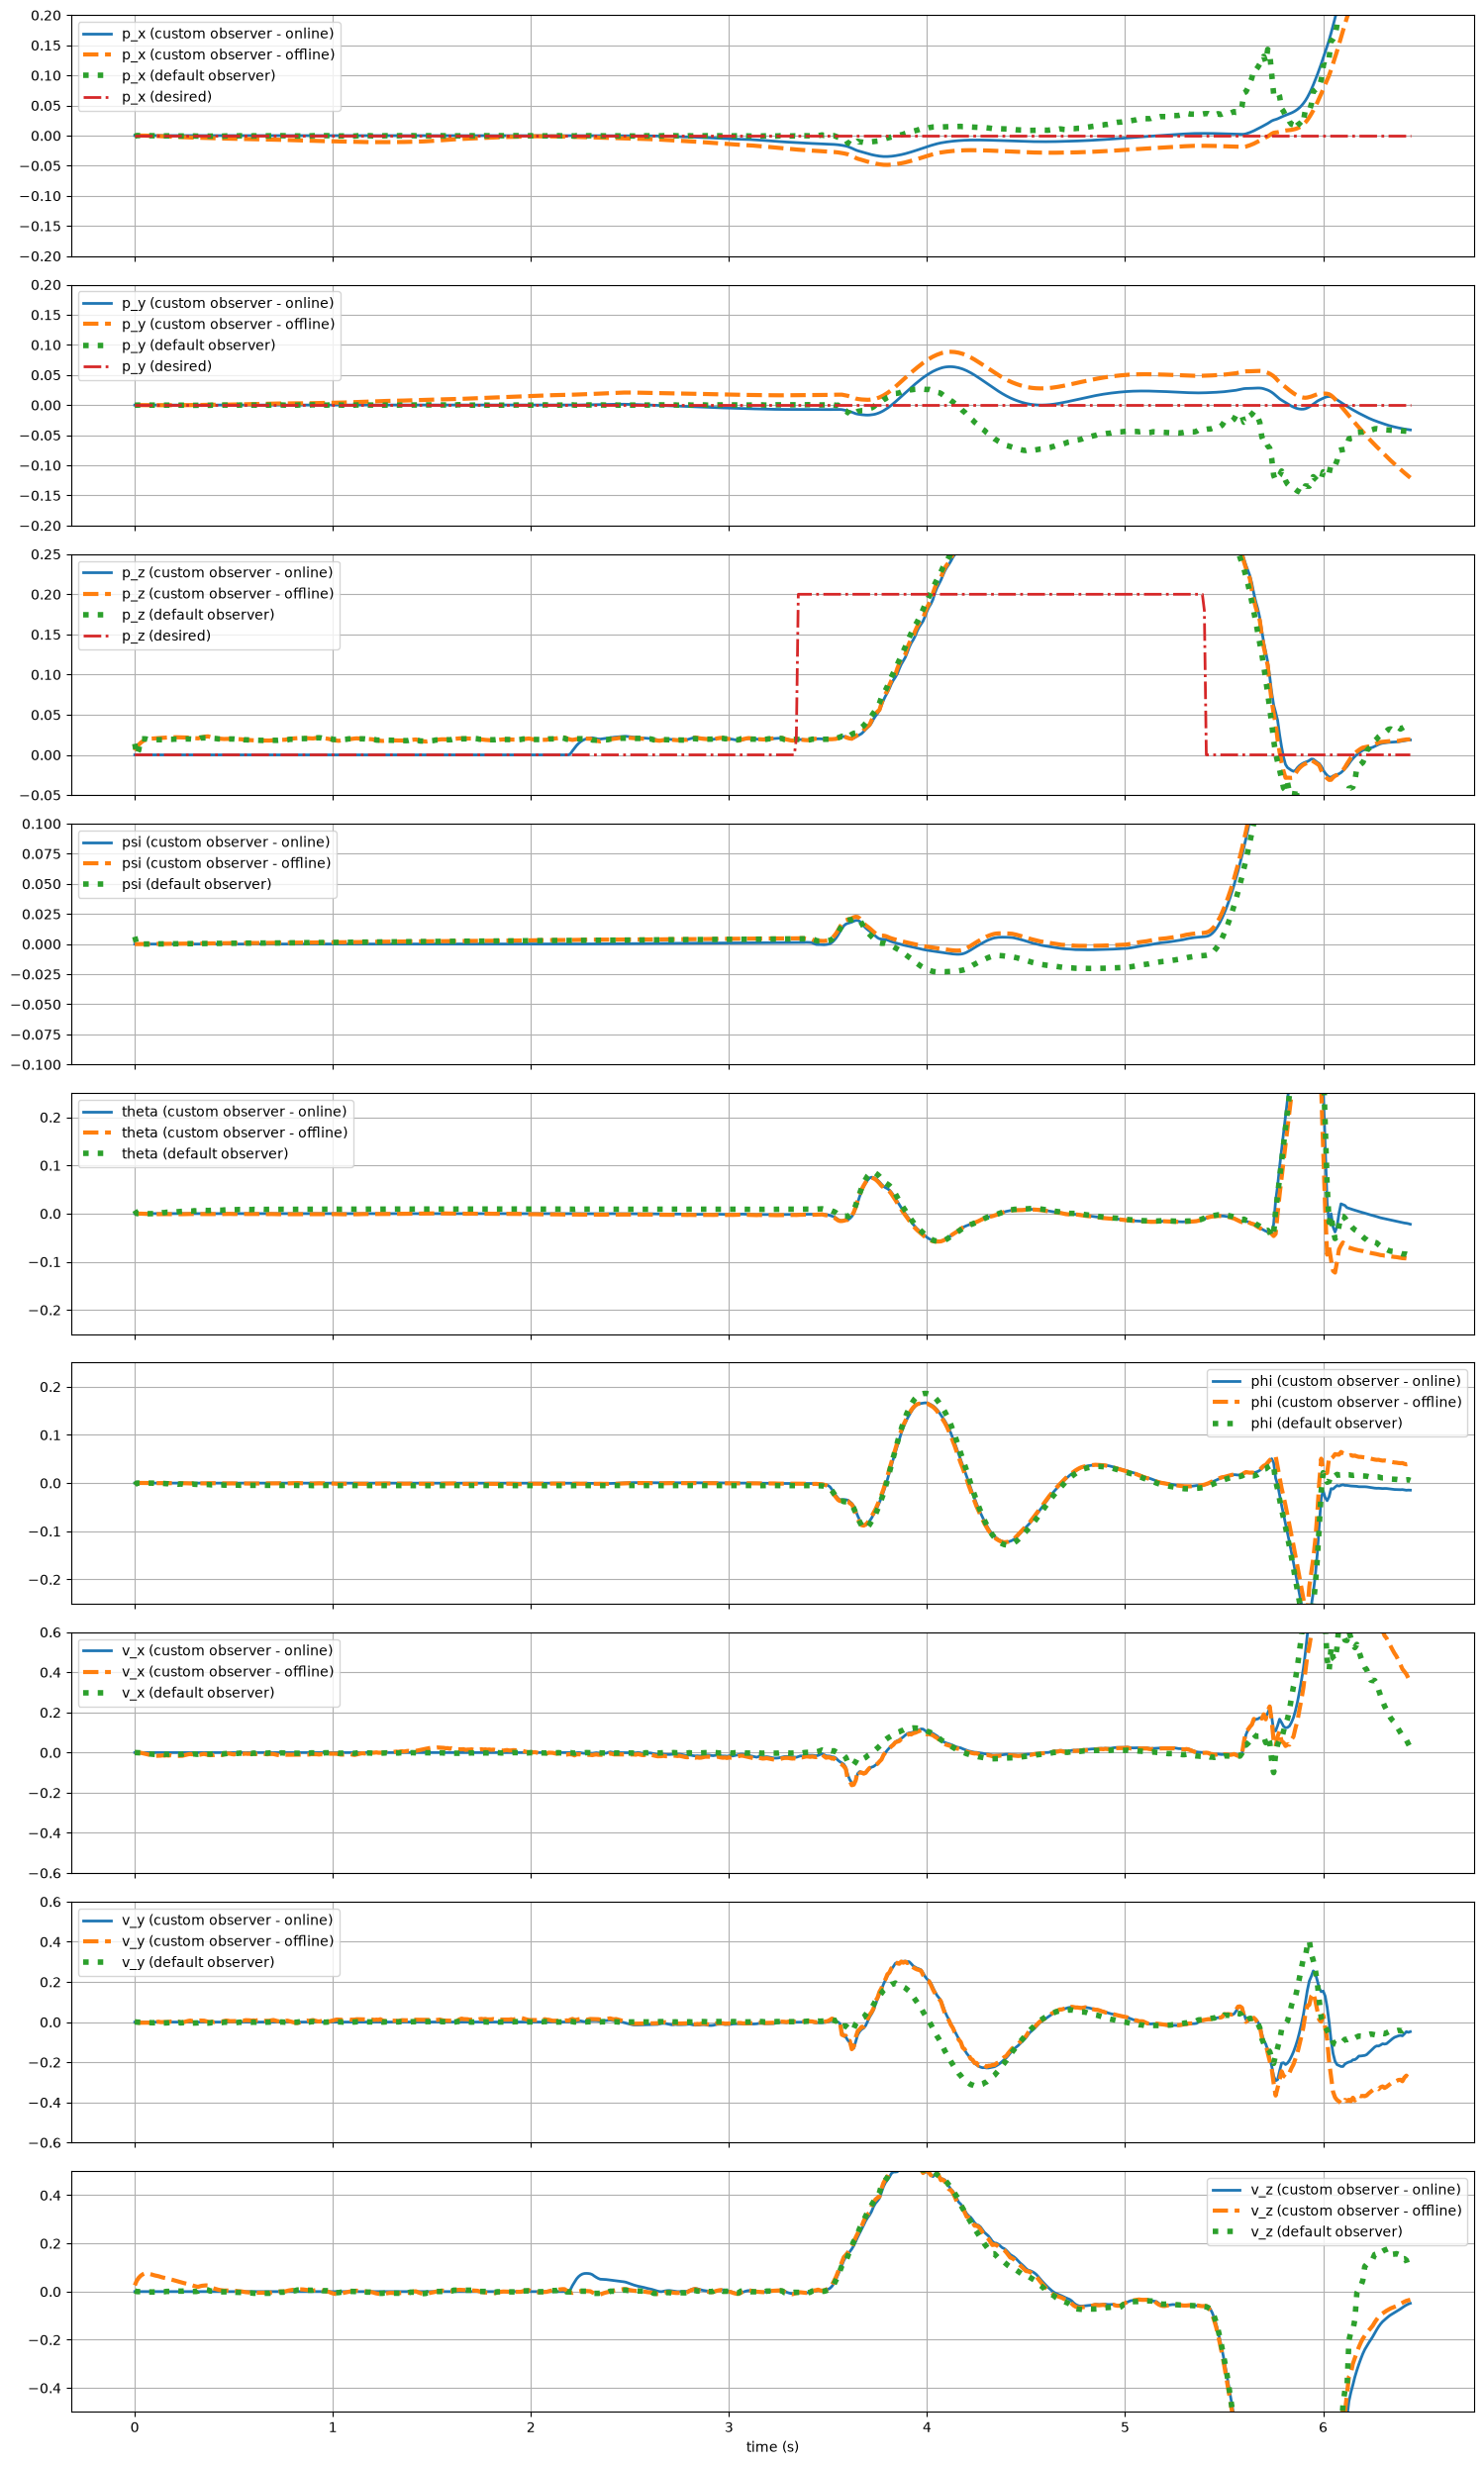

In [11]:
def comparison_plot(t, s_custom, s_default, s_offline, name, ax, s_des=None):
    ax.plot(t, s_custom, label=f'{name} (custom observer - online)', linewidth=2)
    ax.plot(t, s_offline, '--', label=f'{name} (custom observer - offline)', linewidth=3)
    ax.plot(t, s_default, ':', label=f'{name} (default observer)', linewidth=4)
    if s_des is not None:
        ax.plot(t, s_des, '-.', label=f'{name} (desired)', linewidth=2)
    ax.legend()
    ax.grid()

fig, (ax_p_x,
      ax_p_y,
      ax_p_z,
      ax_psi,
      ax_theta,
      ax_phi,
      ax_v_x,
      ax_v_y,
      ax_v_z) = plt.subplots(9, 1, figsize=(15, 25), sharex=True, tight_layout=True)

comparison_plot(t, p_x_custom, p_x_default, p_x_offline, 'p_x', ax_p_x, s_des=p_x_des)
comparison_plot(t, p_y_custom, p_y_default, p_y_offline, 'p_y', ax_p_y, s_des=p_y_des)
comparison_plot(t, p_z_custom, p_z_default, p_z_offline, 'p_z', ax_p_z, s_des=p_z_des)
comparison_plot(t, psi_custom, psi_default, psi_offline, 'psi', ax_psi)
comparison_plot(t, theta_custom, theta_default, theta_offline, 'theta', ax_theta)
comparison_plot(t, phi_custom, phi_default, phi_offline, 'phi', ax_phi)
comparison_plot(t, v_x_custom, v_x_default, v_x_offline, 'v_x', ax_v_x)
comparison_plot(t, v_y_custom, v_y_default, v_y_offline, 'v_y', ax_v_y)
comparison_plot(t, v_z_custom, v_z_default, v_z_offline, 'v_z', ax_v_z)
ax_v_z.set_xlabel('time (s)')

ax_p_x.set_ylim([-0.2, 0.2])
ax_p_y.set_ylim([-0.2, 0.2])
ax_p_z.set_ylim([-0.05, 0.25])
ax_psi.set_ylim([-0.1, 0.1])
ax_theta.set_ylim([-0.25, 0.25])
ax_phi.set_ylim([-0.25, 0.25])
ax_v_x.set_ylim([-0.6, 0.6])
ax_v_y.set_ylim([-0.6, 0.6])
ax_v_z.set_ylim([-0.5, 0.5])

plt.show()

# 3. Flight tests to compare performance at hover

Define colors and styles for all plots.

In [12]:
mocap_color = 'C0'
mocap_linestyle = '-'
mocap_linewidth = 2

default_color = 'C1'
default_linestyle = '--'
default_linewidth = 2

desired_color = 'C2'
desired_linestyle = ':'
desired_linewidth = 4

custom_color = 'C3'
custom_linestyle = '-.'
custom_linewidth = 3

## 3.1 Hover with default controller and observer

I used the default controller and observer with motion capture. I stepped up to 0.50 m, hovered for 10 seconds, and landed in steps. This run was before the startup heading fix, so it includes an initial turn.

Check mocap coverage.

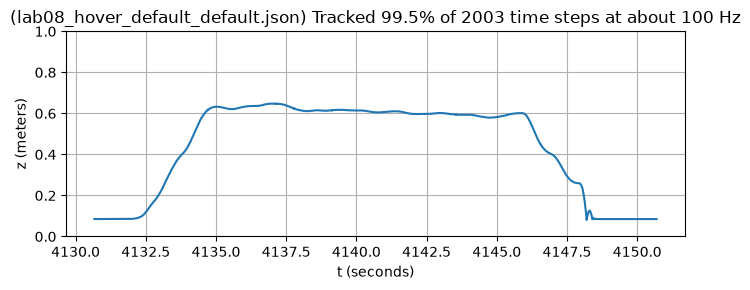

In [13]:
check_mocap_coverage('lab08_hover_default_default.json')

Load flight data.

In [14]:
# Load flight data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('lab08_hover_default_default.json')

# Resample drone data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

# Sync and resample mocap data
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['stateEstimate.z'],
    do_transform=True,      # <-- whether to align mocap data in space (don't change this)
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

# Only look at data from the middle 10 seconds of when the drone was actually flying
only_in_flight(data_drone, data_mocap=data_mocap, t_interval=10.)

Parse flight data.

Note that we have to get the desired position from `ctrltarget.x`, `ctrltarget.y`, and `ctrltarget.z` when the default controller is running. This is because `ae483log.p_x_des`, `ae483log.p_y_des`, and `ae483log.p_z_des` are only set when the custom controller is running.

In [15]:
# time
t = data_drone['time']

# position and orientation from default observer
p_x_default = data_drone['stateEstimate.x']
p_y_default = data_drone['stateEstimate.y']
p_z_default = data_drone['stateEstimate.z']
psi_default = np.deg2rad(data_drone['stateEstimate.yaw'])
theta_default = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi_default = np.deg2rad(data_drone['stateEstimate.roll'])

# position and orientation from the motion capture system
p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

# desired position
p_x_des = data_drone['ctrltarget.x']
p_y_des = data_drone['ctrltarget.y']
p_z_des = data_drone['ctrltarget.z']

Plot position, desired position, and orientation.

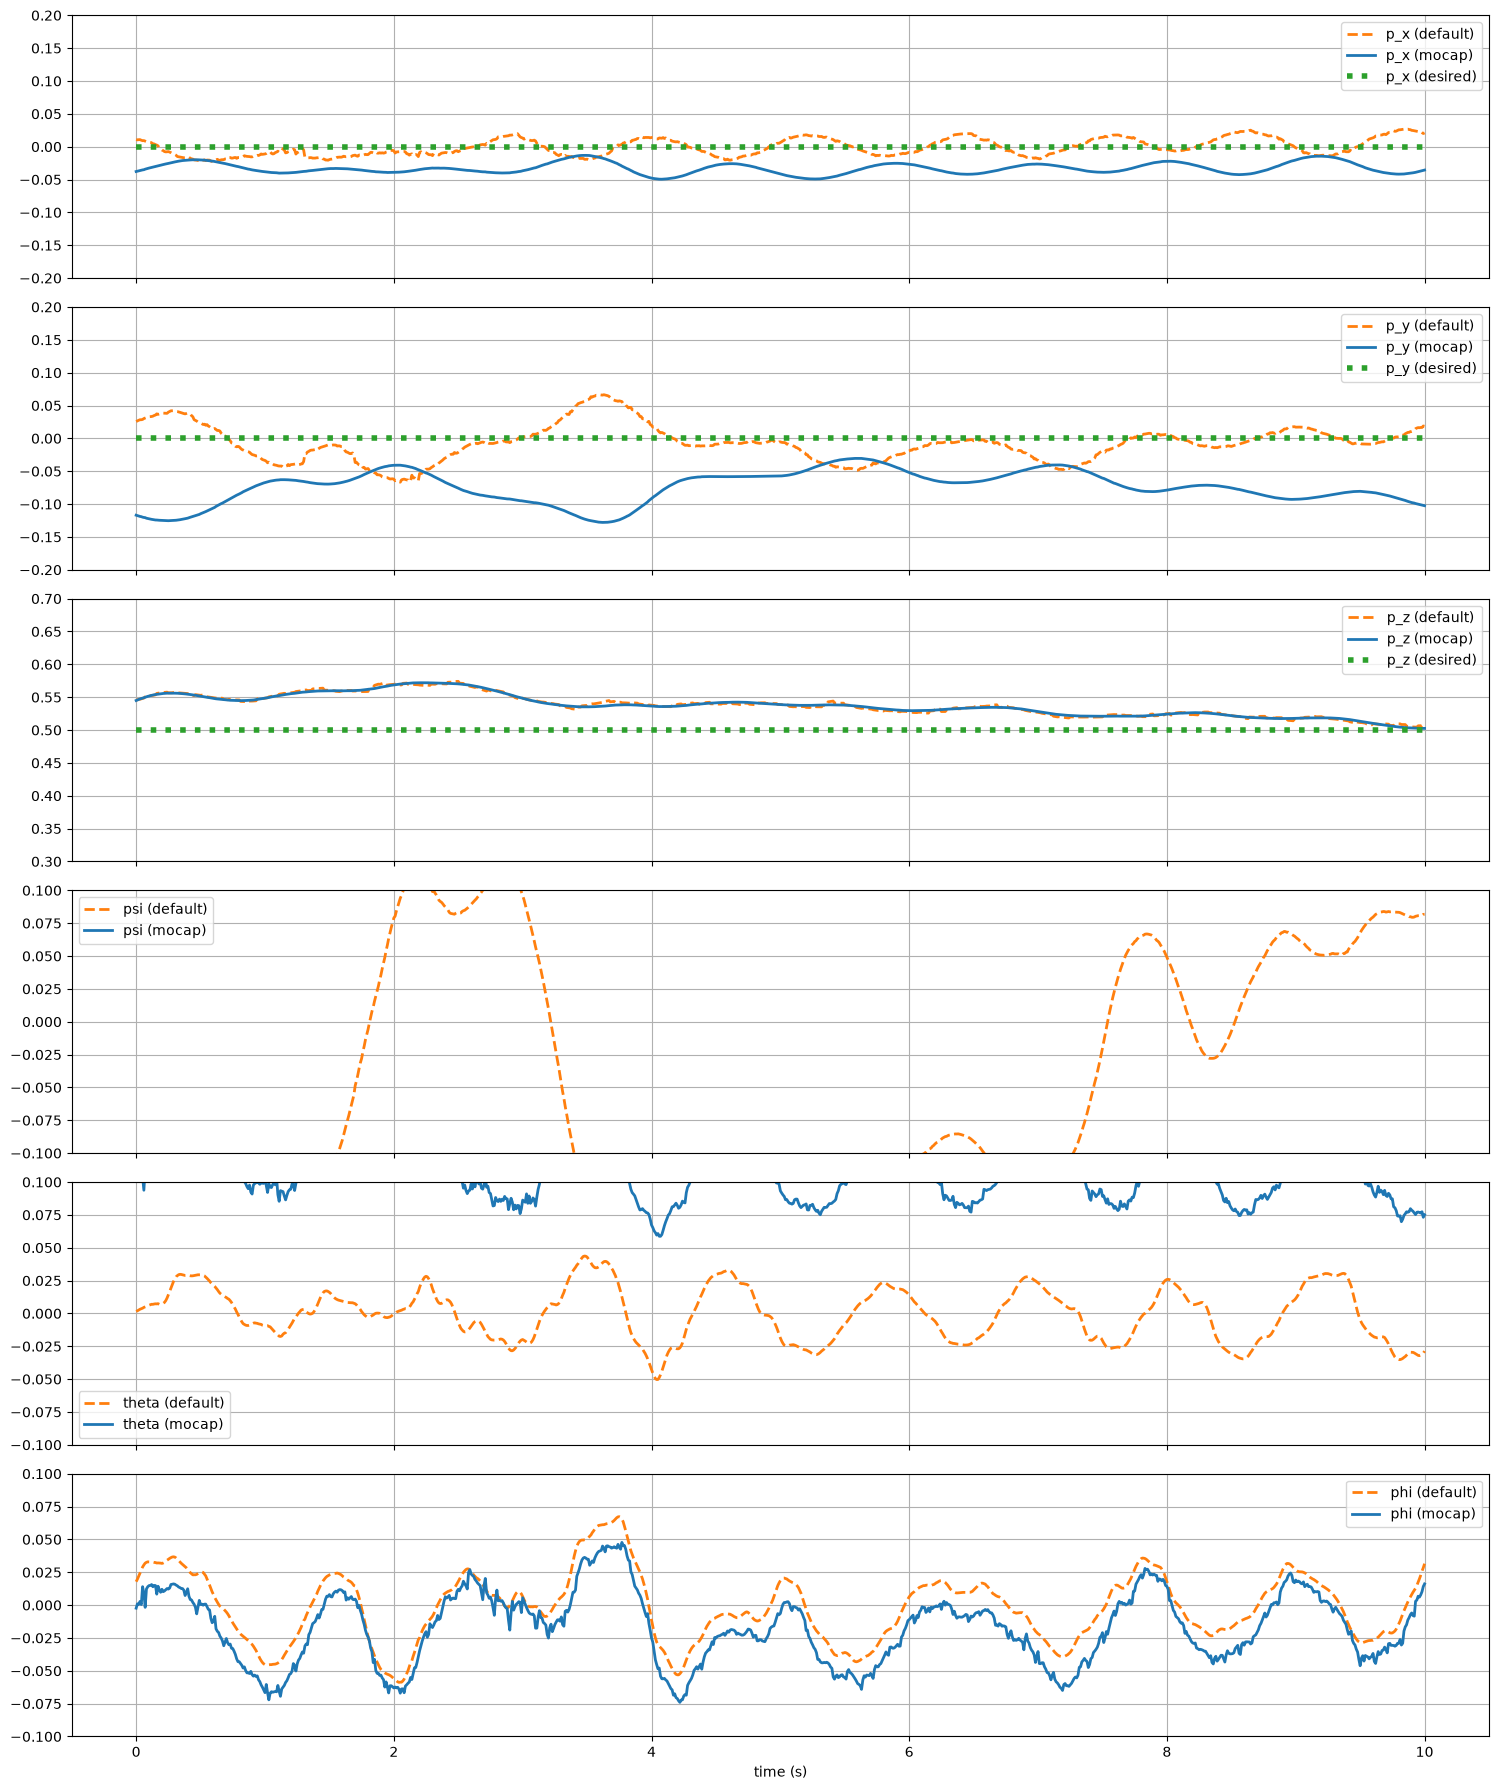

In [16]:
def comparison_plot(t, s_default, s_mocap, name, ax, s_des=None):
    ax.plot(t, s_default, label=f'{name} (default)',
            color=default_color, linestyle=default_linestyle, linewidth=default_linewidth)
    ax.plot(t, s_mocap, label=f'{name} (mocap)',
            color=mocap_color, linestyle=mocap_linestyle, linewidth=mocap_linewidth)
    if s_des is not None:
        ax.plot(t, s_des, label=f'{name} (desired)',
                color=desired_color, linestyle=desired_linestyle, linewidth=desired_linewidth)
    ax.legend()
    ax.grid()

fig, (ax_p_x,
      ax_p_y,
      ax_p_z,
      ax_psi,
      ax_theta,
      ax_phi) = plt.subplots(6, 1, figsize=(15, 18), sharex=True, tight_layout=True)
comparison_plot(t, p_x_default, p_x_mocap, 'p_x', ax_p_x, s_des=p_x_des)
comparison_plot(t, p_y_default, p_y_mocap, 'p_y', ax_p_y, s_des=p_y_des)
comparison_plot(t, p_z_default, p_z_mocap, 'p_z', ax_p_z, s_des=p_z_des)
comparison_plot(t, psi_default, psi_mocap, 'psi', ax_psi)
comparison_plot(t, theta_default, theta_mocap, 'theta', ax_theta)
comparison_plot(t, phi_default, phi_mocap, 'phi', ax_phi)
ax_phi.set_xlabel('time (s)')
ax_p_x.set_ylim([-0.2, 0.2])
ax_p_y.set_ylim([-0.2, 0.2])
ax_p_z.set_ylim([0.3, 0.7])
ax_psi.set_ylim([-0.1, 0.1])
ax_theta.set_ylim([-0.1, 0.1])
ax_phi.set_ylim([-0.1, 0.1])
plt.show()

Compute RMSE between states (from default observer) and their desired values.

In [17]:
print(f'RMSE from t={t[0]} to t={t[-1]} (using estimates from default observer):')
print(f' p_x:   {rmse(p_x_default, p_x_des):7.3f}')
print(f' p_y:   {rmse(p_y_default, p_y_des):7.3f}')
print(f' p_z:   {rmse(p_z_default, p_z_des):7.3f}')
print(f' psi:   {rmse(psi_default, 0.):7.3f}')
print(f' theta: {rmse(theta_default, 0.):7.3f}')
print(f' phi:   {rmse(phi_default, 0.):7.3f}')

RMSE from t=0.0 to t=10.0 (using estimates from default observer):
 p_x:     0.013
 p_y:     0.028
 p_z:     0.041
 psi:     0.143
 theta:   0.020
 phi:     0.026


Compute RMSE between states (from mocap) and their desired values.

In [18]:
print(f'RMSE from t={t[0]} to t={t[-1]} (using estimates from mocap):')
print(f' p_x:   {rmse(p_x_mocap, p_x_des):7.3f}')
print(f' p_y:   {rmse(p_y_mocap, p_y_des):7.3f}')
print(f' p_z:   {rmse(p_z_mocap, p_z_des):7.3f}')
print(f' psi:   {rmse(psi_mocap, 0.):7.3f}')
print(f' theta: {rmse(theta_mocap, 0.):7.3f}')
print(f' phi:   {rmse(phi_mocap, 0.):7.3f}')

RMSE from t=0.0 to t=10.0 (using estimates from mocap):
 p_x:     0.034
 p_y:     0.078
 p_z:     0.041
 psi:     2.936
 theta:   0.110
 phi:     0.032


## 3.2 Hover with custom controller and default observer

I repeated the 10-second hover at 0.50 m with my custom controller, the default observer, and motion capture. This was the successful repeat after the startup heading fix.

Check mocap coverage.

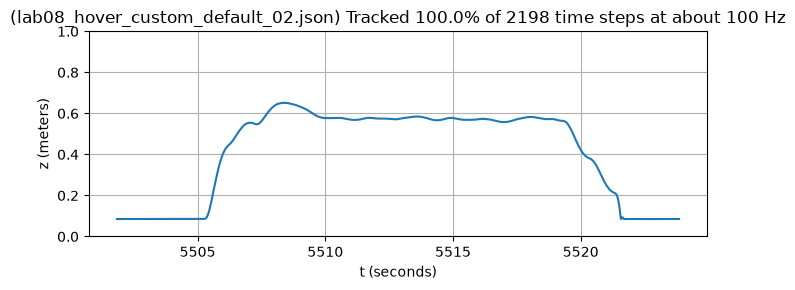

In [19]:
check_mocap_coverage('lab08_hover_custom_default_02.json')

Load flight data.

In [20]:
# Load flight data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('lab08_hover_custom_default_02.json')

# Resample drone data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

# Sync and resample mocap data
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['ae483log.p_z'],
    do_transform=True,      # <-- whether to align mocap data in space (don't change this)
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

# Only look at data from the middle 10 seconds of when the drone was actually flying
only_in_flight(data_drone, data_mocap=data_mocap, t_interval=10.)

Parse flight data.

In [21]:
# time
t = data_drone['time']

# position and orientation from default observer
p_x_default = data_drone['ae483log.p_x']
p_y_default = data_drone['ae483log.p_y']
p_z_default = data_drone['ae483log.p_z']
psi_default = data_drone['ae483log.psi']
theta_default = data_drone['ae483log.theta']
phi_default = data_drone['ae483log.phi']

# position and orientation from the motion capture system
p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

Plot position, desired position, and orientation.

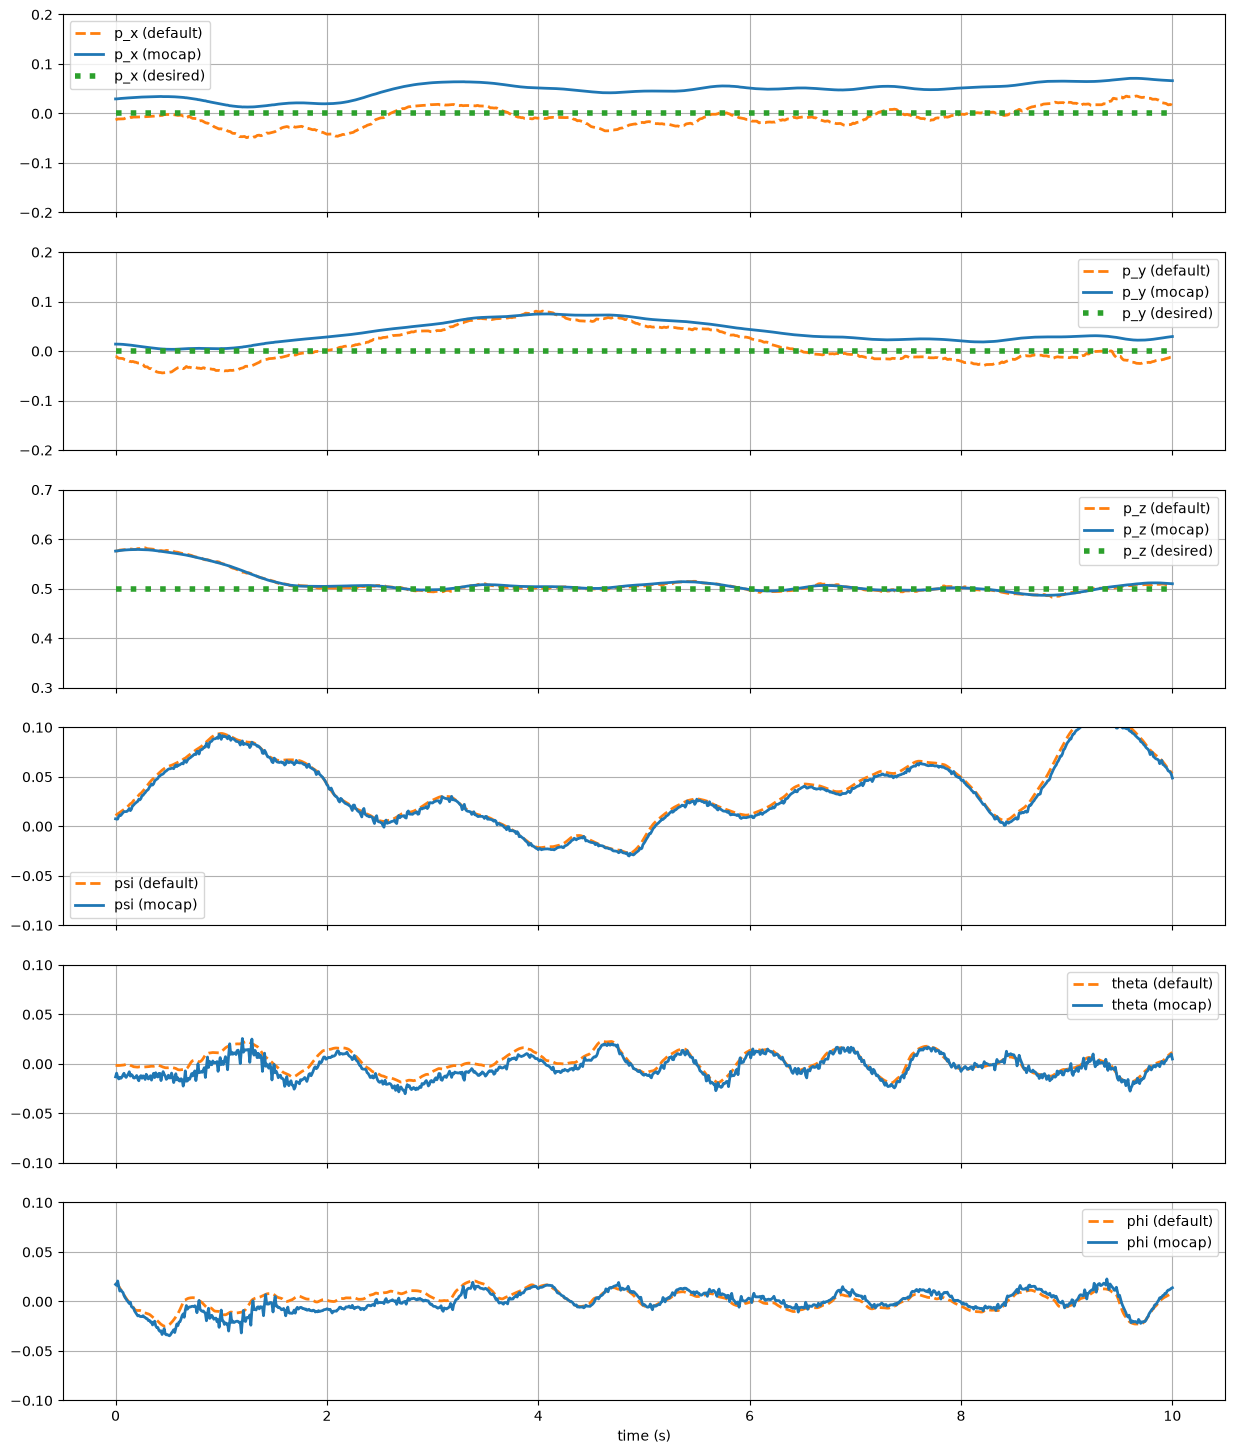

In [22]:
def comparison_plot(t, s_default, s_mocap, name, ax, s_des=None):
    ax.plot(t, s_default, label=f'{name} (default)',
            color=default_color, linestyle=default_linestyle, linewidth=default_linewidth)
    ax.plot(t, s_mocap, label=f'{name} (mocap)',
            color=mocap_color, linestyle=mocap_linestyle, linewidth=mocap_linewidth)
    if s_des is not None:
        ax.plot(t, s_des, label=f'{name} (desired)',
                color=desired_color, linestyle=desired_linestyle, linewidth=desired_linewidth)
    ax.legend()
    ax.grid()

fig, (ax_p_x,
      ax_p_y,
      ax_p_z,
      ax_psi,
      ax_theta,
      ax_phi) = plt.subplots(6, 1, figsize=(15, 18), sharex=True)
comparison_plot(t, p_x_default, p_x_mocap, 'p_x', ax_p_x, s_des=p_x_des)
comparison_plot(t, p_y_default, p_y_mocap, 'p_y', ax_p_y, s_des=p_y_des)
comparison_plot(t, p_z_default, p_z_mocap, 'p_z', ax_p_z, s_des=p_z_des)
comparison_plot(t, psi_default, psi_mocap, 'psi', ax_psi)
comparison_plot(t, theta_default, theta_mocap, 'theta', ax_theta)
comparison_plot(t, phi_default, phi_mocap, 'phi', ax_phi)
ax_phi.set_xlabel('time (s)')
ax_p_x.set_ylim([-0.2, 0.2])
ax_p_y.set_ylim([-0.2, 0.2])
ax_p_z.set_ylim([0.3, 0.7])
ax_psi.set_ylim([-0.1, 0.1])
ax_theta.set_ylim([-0.1, 0.1])
ax_phi.set_ylim([-0.1, 0.1])
plt.show()

Compute RMSE between states (from default observer) and their desired values.

In [23]:
print(f'RMSE from t={t[0]} to t={t[-1]} (using estimates from default observer):')
print(f' p_x:   {rmse(p_x_default, p_x_des):7.3f}')
print(f' p_y:   {rmse(p_y_default, p_y_des):7.3f}')
print(f' p_z:   {rmse(p_z_default, p_z_des):7.3f}')
print(f' psi:   {rmse(psi_default, 0.):7.3f}')
print(f' theta: {rmse(theta_default, 0.):7.3f}')
print(f' phi:   {rmse(phi_default, 0.):7.3f}')

RMSE from t=0.0 to t=10.0 (using estimates from default observer):
 p_x:     0.021
 p_y:     0.037
 p_z:     0.025
 psi:     0.051
 theta:   0.010
 phi:     0.009


Compute RMSE between states (from mocap) and their desired values.

In [24]:
print(f'RMSE from t={t[0]} to t={t[-1]} (using estimates from mocap):')
print(f' p_x:   {rmse(p_x_mocap, p_x_des):7.3f}')
print(f' p_y:   {rmse(p_y_mocap, p_y_des):7.3f}')
print(f' p_z:   {rmse(p_z_mocap, p_z_des):7.3f}')
print(f' psi:   {rmse(psi_mocap, 0.):7.3f}')
print(f' theta: {rmse(theta_mocap, 0.):7.3f}')
print(f' phi:   {rmse(phi_mocap, 0.):7.3f}')

RMSE from t=0.0 to t=10.0 (using estimates from mocap):
 p_x:     0.049
 p_y:     0.042
 p_z:     0.025
 psi:     0.048
 theta:   0.012
 phi:     0.010


## 3.3 Hover with custom controller and observer

I repeated the 10-second hover at 0.50 m with my custom controller and observer, and motion capture. I kept the same custom controller gains and takeoff and landing commands as in Section 3.2.

Check mocap coverage.

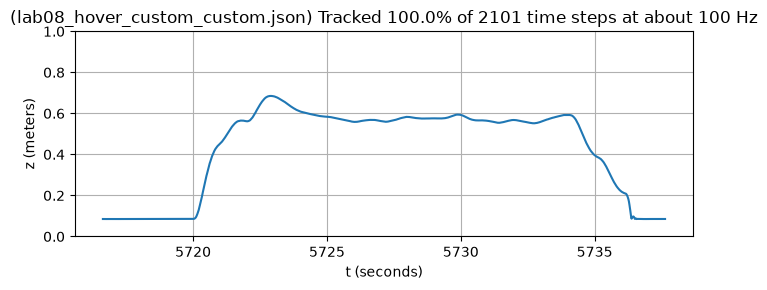

In [25]:
check_mocap_coverage('lab08_hover_custom_custom.json')

Load flight data.

In [26]:
# Load flight data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('lab08_hover_custom_custom.json')

# Resample drone data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

# Sync and resample mocap data
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['ae483log.p_z'],
    do_transform=True,      # <-- whether to align mocap data in space (don't change this)
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)


# Only look at data from the middle 10 seconds of when the drone was actually flying
only_in_flight(data_drone, data_mocap=data_mocap, t_interval=10.)

Parse flight data:
* Estimates from the custom observer implemented online are labled `_custom`.
* Estimates from the default observer are labeled `_default`.

In [27]:
# time
t = data_drone['time']

# position and orientation from custom observer
p_x_custom = data_drone['ae483log.p_x']
p_y_custom = data_drone['ae483log.p_y']
p_z_custom = data_drone['ae483log.p_z']
psi_custom = data_drone['ae483log.psi']
theta_custom = data_drone['ae483log.theta']
phi_custom = data_drone['ae483log.phi']

# position and orientation from default observer
p_x_default = data_drone['stateEstimate.x']
p_y_default = data_drone['stateEstimate.y']
p_z_default = data_drone['stateEstimate.z']
psi_default = np.deg2rad(data_drone['stateEstimate.yaw'])
theta_default = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi_default = np.deg2rad(data_drone['stateEstimate.roll'])

# position and orientation from the motion capture system
p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

Plot position, desired position, and orientation.

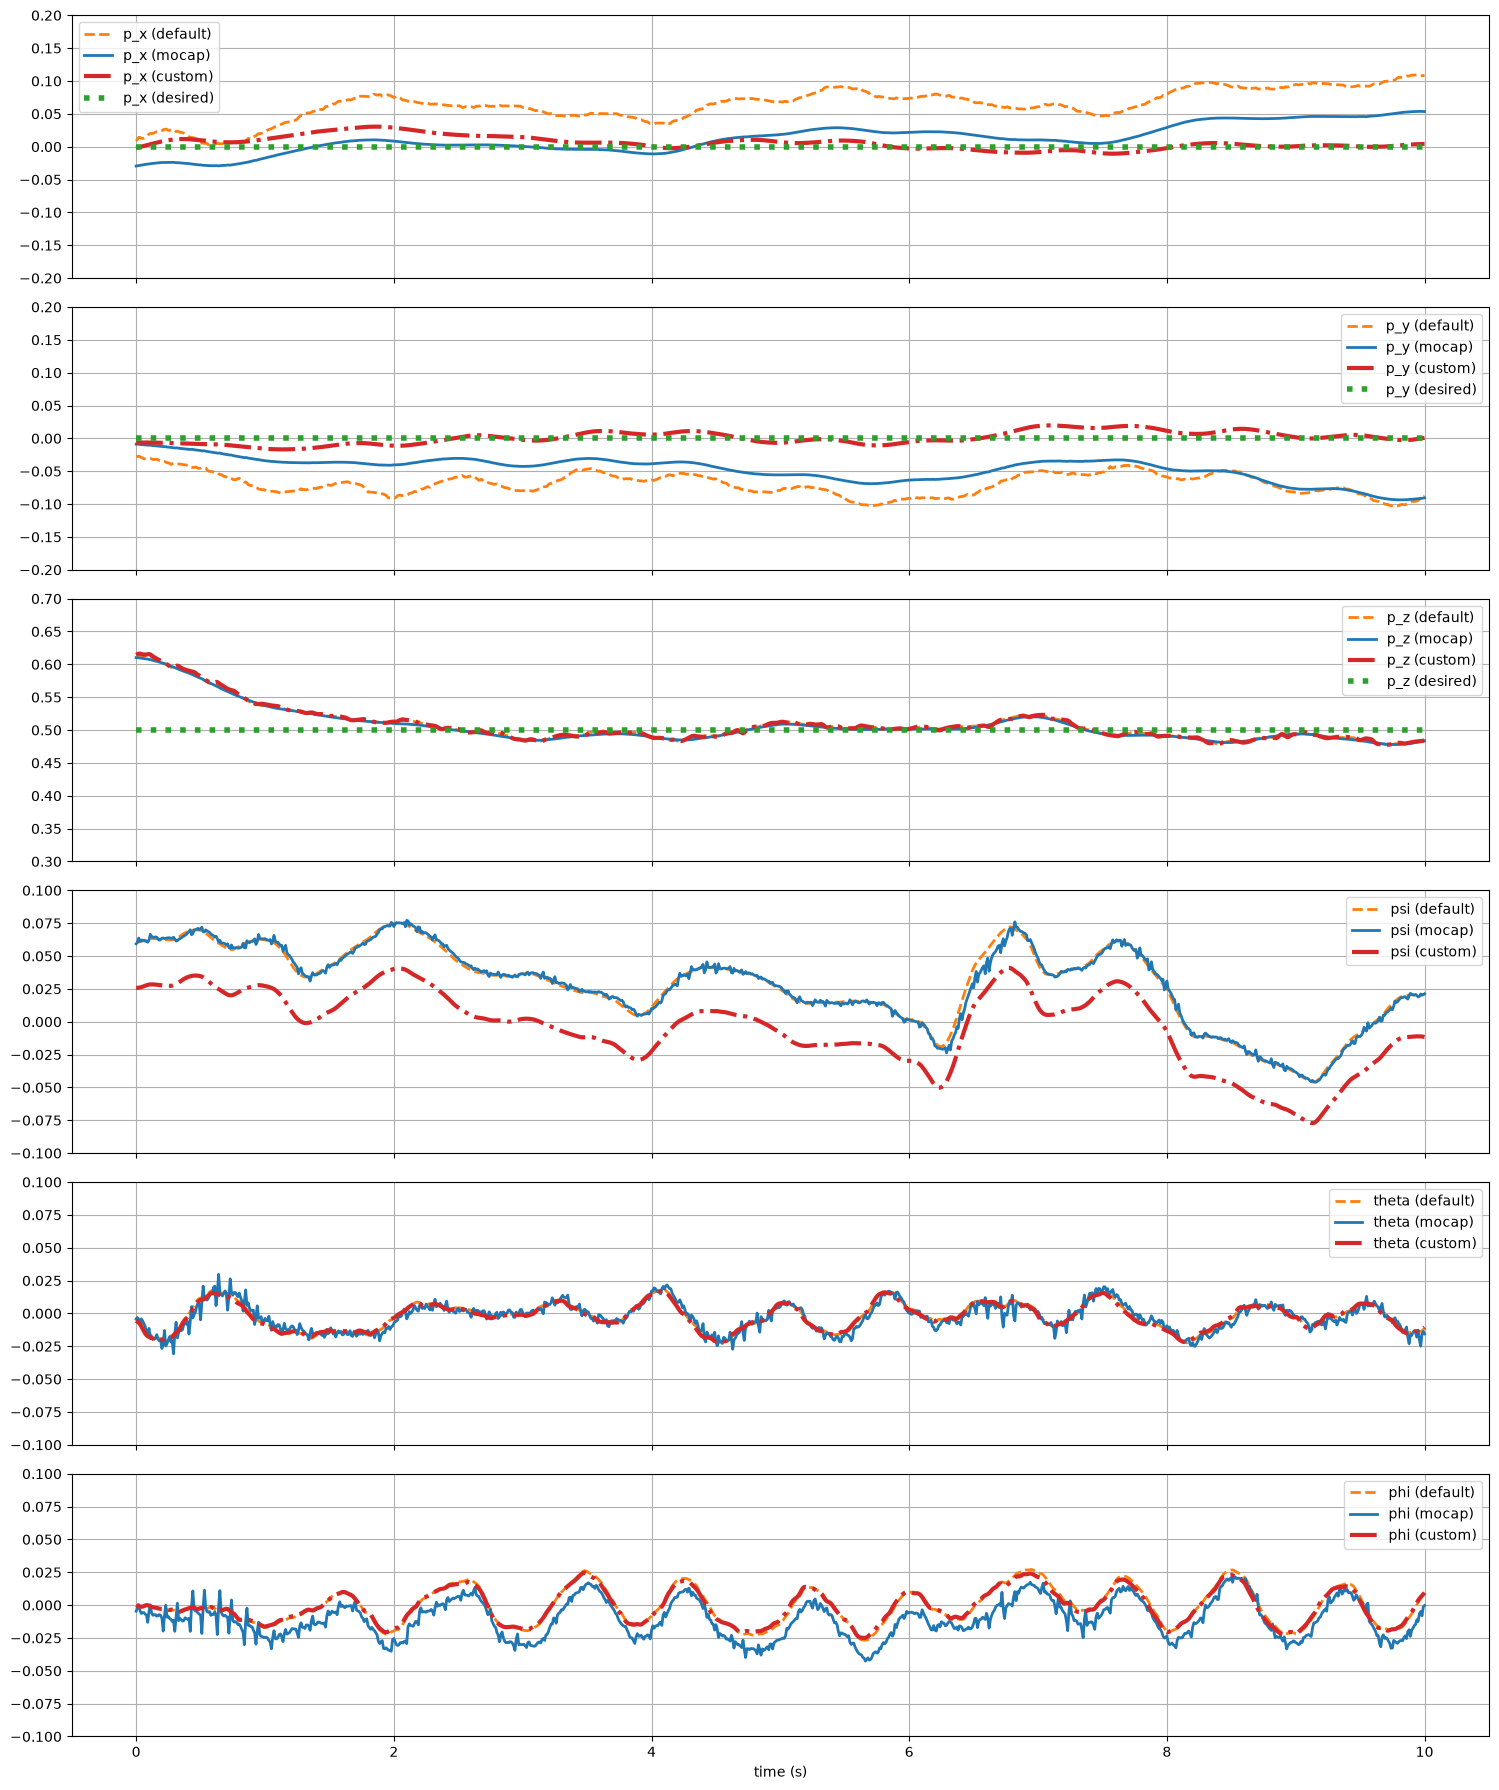

In [28]:
def comparison_plot(t, s_custom, s_default, s_mocap, name, ax, s_des=None):
    ax.plot(t, s_default, label=f'{name} (default)',
            color=default_color, linestyle=default_linestyle, linewidth=default_linewidth)
    ax.plot(t, s_mocap, label=f'{name} (mocap)',
            color=mocap_color, linestyle=mocap_linestyle, linewidth=mocap_linewidth)
    ax.plot(t, s_custom, label=f'{name} (custom)',
            color=custom_color, linestyle=custom_linestyle, linewidth=custom_linewidth)
    if s_des is not None:
        ax.plot(t, s_des, label=f'{name} (desired)',
                color=desired_color, linestyle=desired_linestyle, linewidth=desired_linewidth)
    ax.legend()
    ax.grid()

fig, (ax_p_x,
      ax_p_y,
      ax_p_z,
      ax_psi,
      ax_theta,
      ax_phi) = plt.subplots(6, 1, figsize=(15, 18), sharex=True, tight_layout=True)
comparison_plot(t, p_x_custom, p_x_default, p_x_mocap, 'p_x', ax_p_x, s_des=p_x_des)
comparison_plot(t, p_y_custom, p_y_default, p_y_mocap, 'p_y', ax_p_y, s_des=p_y_des)
comparison_plot(t, p_z_custom, p_z_default, p_z_mocap, 'p_z', ax_p_z, s_des=p_z_des)
comparison_plot(t, psi_custom, psi_default, psi_mocap, 'psi', ax_psi)
comparison_plot(t, theta_custom, theta_default, theta_mocap, 'theta', ax_theta)
comparison_plot(t, phi_custom, phi_default, phi_mocap, 'phi', ax_phi)
ax_phi.set_xlabel('time (s)')
ax_p_x.set_ylim([-0.2, 0.2])
ax_p_y.set_ylim([-0.2, 0.2])
ax_p_z.set_ylim([0.3, 0.7])
ax_psi.set_ylim([-0.1, 0.1])
ax_theta.set_ylim([-0.1, 0.1])
ax_phi.set_ylim([-0.1, 0.1])
plt.show()

Compute RMSE between states (from custom observer) and their desired values.

In [29]:
print(f'RMSE from t={t[0]} to t={t[-1]} (using estimates from default observer):')
print(f' p_x:   {rmse(p_x_custom, p_x_des):7.3f}')
print(f' p_y:   {rmse(p_y_custom, p_y_des):7.3f}')
print(f' p_z:   {rmse(p_z_custom, p_z_des):7.3f}')
print(f' psi:   {rmse(psi_custom, 0.):7.3f}')
print(f' theta: {rmse(theta_custom, 0.):7.3f}')
print(f' phi:   {rmse(phi_custom, 0.):7.3f}')

RMSE from t=0.0 to t=10.0 (using estimates from default observer):
 p_x:     0.011
 p_y:     0.010
 p_z:     0.029
 psi:     0.029
 theta:   0.010
 phi:     0.013


Compute RMSE between states (from mocap) and their desired values.

In [30]:
print(f'RMSE from t={t[0]} to t={t[-1]} (using estimates from mocap):')
print(f' p_x:   {rmse(p_x_mocap, p_x_des):7.3f}')
print(f' p_y:   {rmse(p_y_mocap, p_y_des):7.3f}')
print(f' p_z:   {rmse(p_z_mocap, p_z_des):7.3f}')
print(f' psi:   {rmse(psi_mocap, 0.):7.3f}')
print(f' theta: {rmse(theta_mocap, 0.):7.3f}')
print(f' phi:   {rmse(phi_mocap, 0.):7.3f}')

RMSE from t=0.0 to t=10.0 (using estimates from mocap):
 p_x:     0.025
 p_y:     0.050
 p_z:     0.028
 psi:     0.041
 theta:   0.011
 phi:     0.018


## 3.4 Summary and discussion

RMSE in each component of position and of orientation **(computed with respect to state estimates from an observer)**:

|  | $p_x$ | $p_y$ | $p_z$ | $\psi$ | $\theta$ | $\phi$ |
| --: | :--: | :--: | :--: | :--: | :--: | :--: |
| RMSE in hover test (default controller, default observer) | 0.013 | 0.028 | 0.041 | 0.143 | 0.020 | 0.026 |
| RMSE in hover test (custom controller, default observer) | 0.021 | 0.037 | 0.025 | 0.051 | 0.010 | 0.009 |
| RMSE in hover test (custom controller, custom observer) | 0.011 | 0.010 | 0.029 | 0.029 | 0.010 | 0.013 |

**Modify the text in this cell** to answer the following questions:

* Are you able to match the performance of the default controller and observer (top row) with your controller and observer (bottom row)? Do the results when using the custom controller with the default observer (middle row) help explain any differences in performance?
* What about your observer design (if anything) did you have to change in order to get your custom controller and observer to work well? Why were these changes necessary?

My observer estimates did better than the defaults. You can see that w the custom controller but with the default observer there were bigger x and y errors but as soon as I started to use my own custome observer you can see that it performed much better.

I kept the same observer weights and gains from lab 7. But in the  C code, I used the same 0.50 m equilibrium height and a 0.002 s time step instead of the offline 0.01 s step. 

RMSE in each component of position and of orientation **(computed with respect to state estimates from mocap)**:

|  | $p_x$ | $p_y$ | $p_z$ | $\psi$ | $\theta$ | $\phi$ |
| --: | :--: | :--: | :--: | :--: | :--: | :--: |
| RMSE in hover test (default controller, default observer) | 0.034 | 0.078 | 0.041 | 2.936 | 0.110 | 0.032 |
| RMSE in hover test (custom controller, default observer) | 0.049 | 0.042 | 0.025 | 0.048 | 0.012 | 0.010 |
| RMSE in hover test (custom controller, custom observer) | 0.025 | 0.050 | 0.028 | 0.041 | 0.011 | 0.018 |

**Modify the text in this cell** to answer the following questions:

* In what ways are the RMSE values in this table (computed with respect to state estimates from mocap) significantly different from the RMSE values in the other table (computed with respect to state estimates from an observer)? Why?

Mocap gave bigger x and y errors, but the height errors were about the same. For my custom observer, the y error was 5 cm using mocap but only 1 cm using the observer. The observer can miss horizontal drift, so its own errors can look small and so its not very accurate as the mocap. 

Mocap tracks pos separately so it is much easier to pick up drift. Height agrees better bc the sensor is looking directly at the floor.

# 4. Flight test while moving in squares

Check mocap coverage.

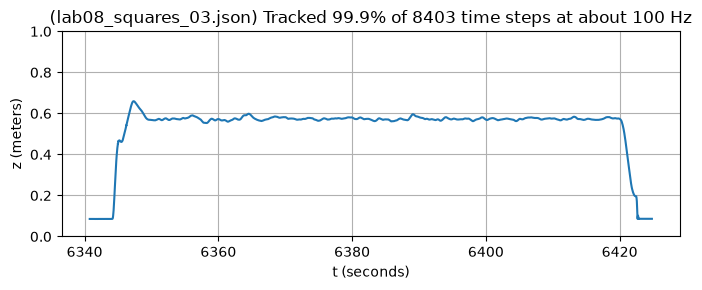

In [31]:
check_mocap_coverage('lab08_squares_03.json')

Load flight data.

In [32]:
# Load flight data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('lab08_squares_03.json')

# Resample drone data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0., # <-- FIXME
    t_max_offset=0., # <-- FIXME
)

# Sync and resample mocap data
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['ae483log.p_z'],
    do_transform=True,      # <-- whether to align mocap data in space (don't change this)
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

# Only look at data from when the drone was actually flying
only_in_flight(data_drone, data_mocap=data_mocap)

Parse flight data.

In [33]:
# time
t = data_drone['time']

# position and orientation from custom observer
p_x_custom = data_drone['ae483log.p_x']
p_y_custom = data_drone['ae483log.p_y']
p_z_custom = data_drone['ae483log.p_z']
psi_custom = data_drone['ae483log.psi']
theta_custom = data_drone['ae483log.theta']
phi_custom = data_drone['ae483log.phi']

# position and orientation from default observer
p_x_default = data_drone['stateEstimate.x']
p_y_default = data_drone['stateEstimate.y']
p_z_default = data_drone['stateEstimate.z']
psi_default = np.deg2rad(data_drone['stateEstimate.yaw'])
theta_default = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi_default = np.deg2rad(data_drone['stateEstimate.roll'])

# position and orientation from the motion capture system
p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

Plot position, desired position, and orientation (both from default and custom observer) as functions of time.

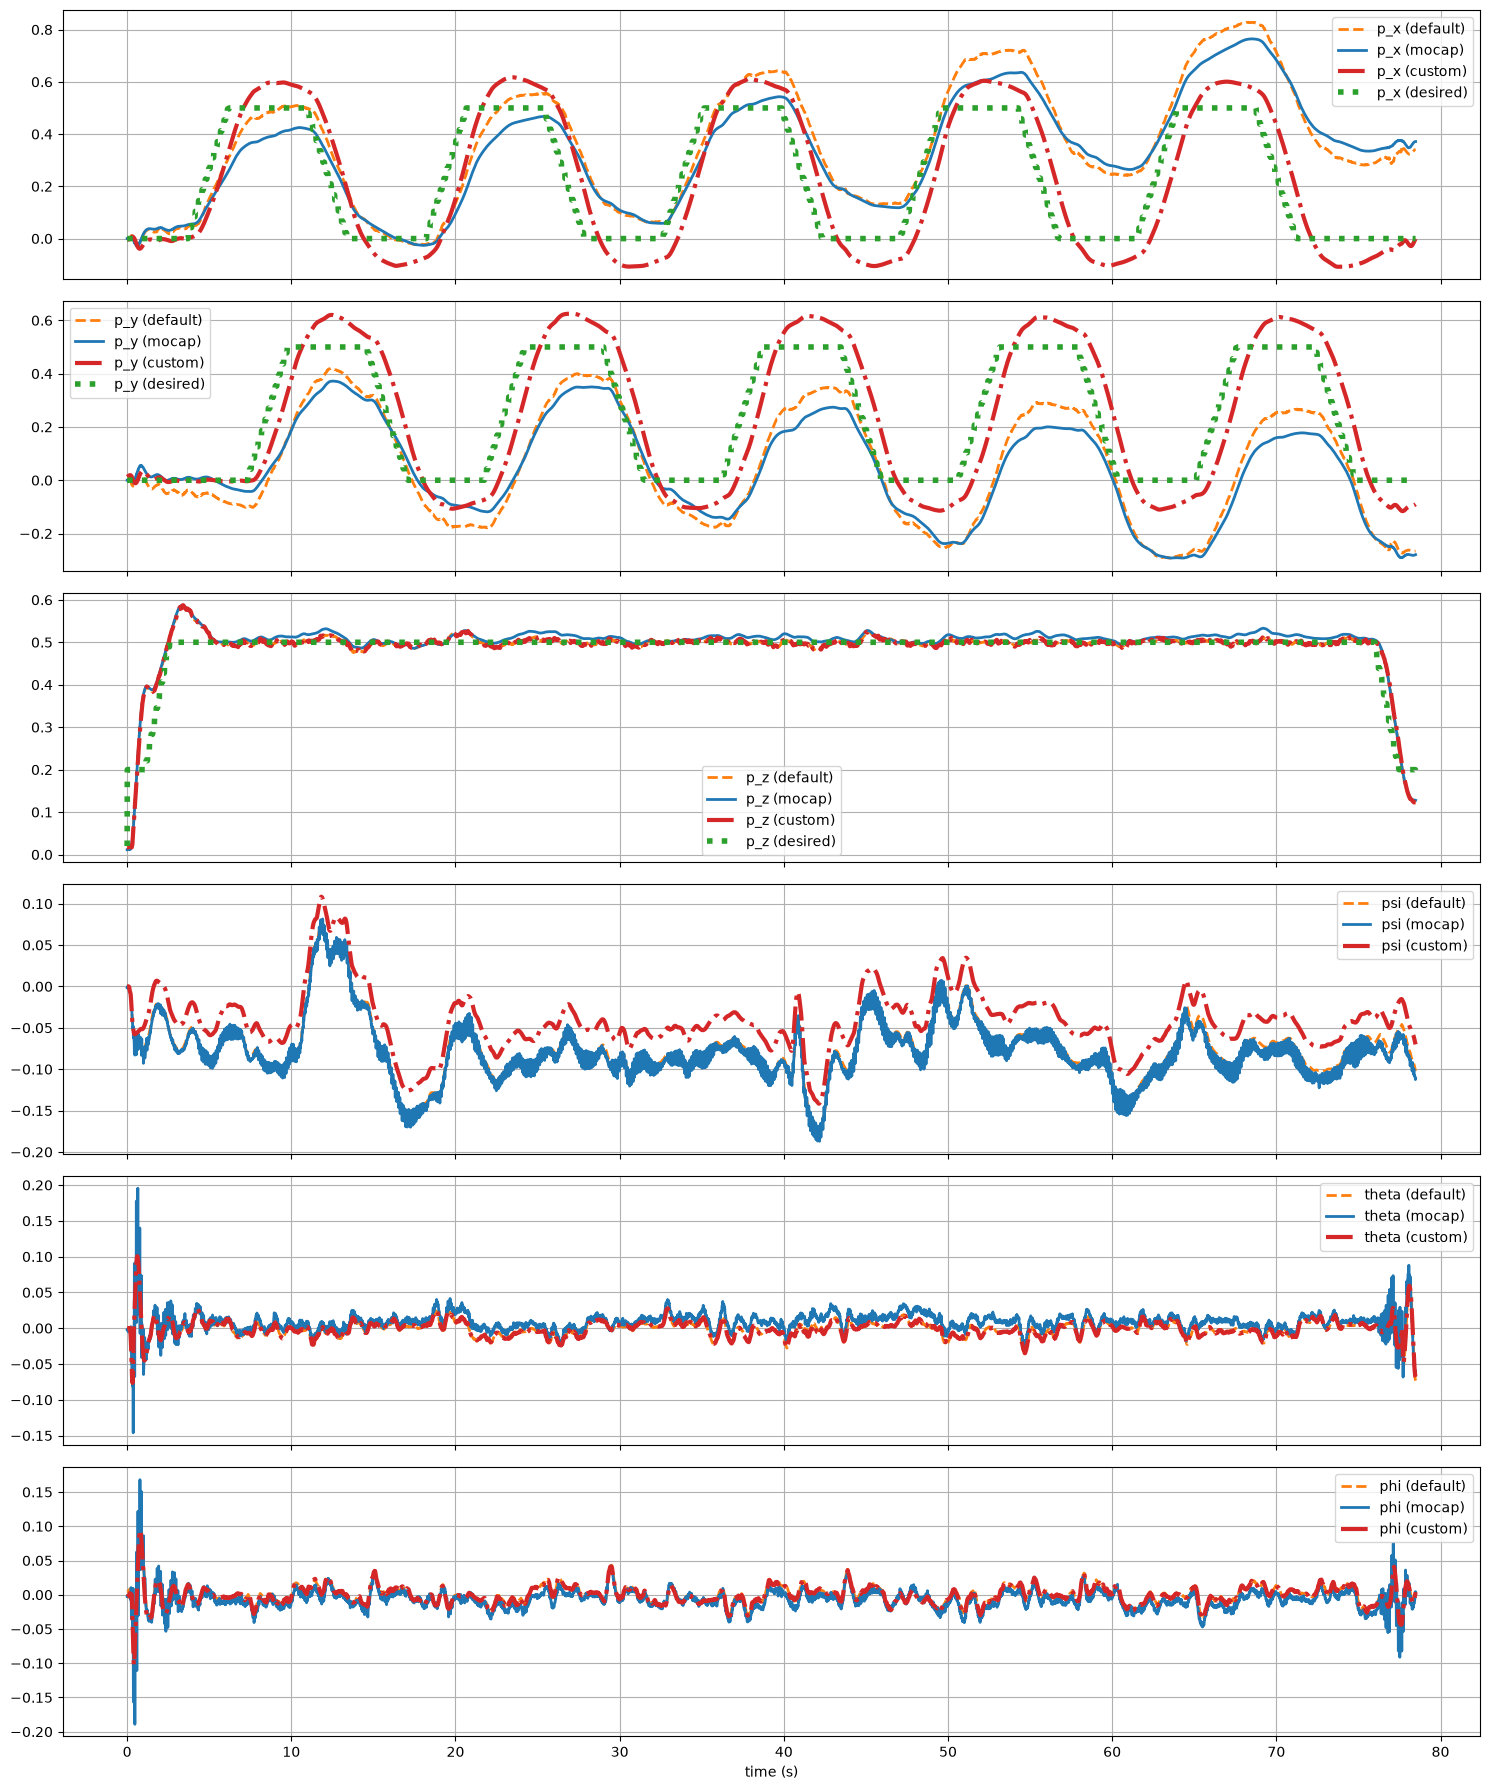

In [34]:
def comparison_plot(t, s_custom, s_default, s_mocap, name, ax, s_des=None):
    ax.plot(t, s_default, label=f'{name} (default)',
            color=default_color, linestyle=default_linestyle, linewidth=default_linewidth)
    ax.plot(t, s_mocap, label=f'{name} (mocap)',
            color=mocap_color, linestyle=mocap_linestyle, linewidth=mocap_linewidth)
    ax.plot(t, s_custom, label=f'{name} (custom)',
            color=custom_color, linestyle=custom_linestyle, linewidth=custom_linewidth)
    if s_des is not None:
        ax.plot(t, s_des, label=f'{name} (desired)',
                color=desired_color, linestyle=desired_linestyle, linewidth=desired_linewidth)
    ax.legend()
    ax.grid()

fig, (ax_p_x,
      ax_p_y,
      ax_p_z,
      ax_psi,
      ax_theta,
      ax_phi) = plt.subplots(6, 1, figsize=(15, 18), sharex=True, tight_layout=True)
comparison_plot(t, p_x_custom, p_x_default, p_x_mocap, 'p_x', ax_p_x, s_des=p_x_des)
comparison_plot(t, p_y_custom, p_y_default, p_y_mocap, 'p_y', ax_p_y, s_des=p_y_des)
comparison_plot(t, p_z_custom, p_z_default, p_z_mocap, 'p_z', ax_p_z, s_des=p_z_des)
comparison_plot(t, psi_custom, psi_default, psi_mocap, 'psi', ax_psi)
comparison_plot(t, theta_custom, theta_default, theta_mocap, 'theta', ax_theta)
comparison_plot(t, phi_custom, phi_default, phi_mocap, 'phi', ax_phi)
ax_phi.set_xlabel('time (s)')
plt.show()

Plot top-down position and desired position (both from default and custom observer).

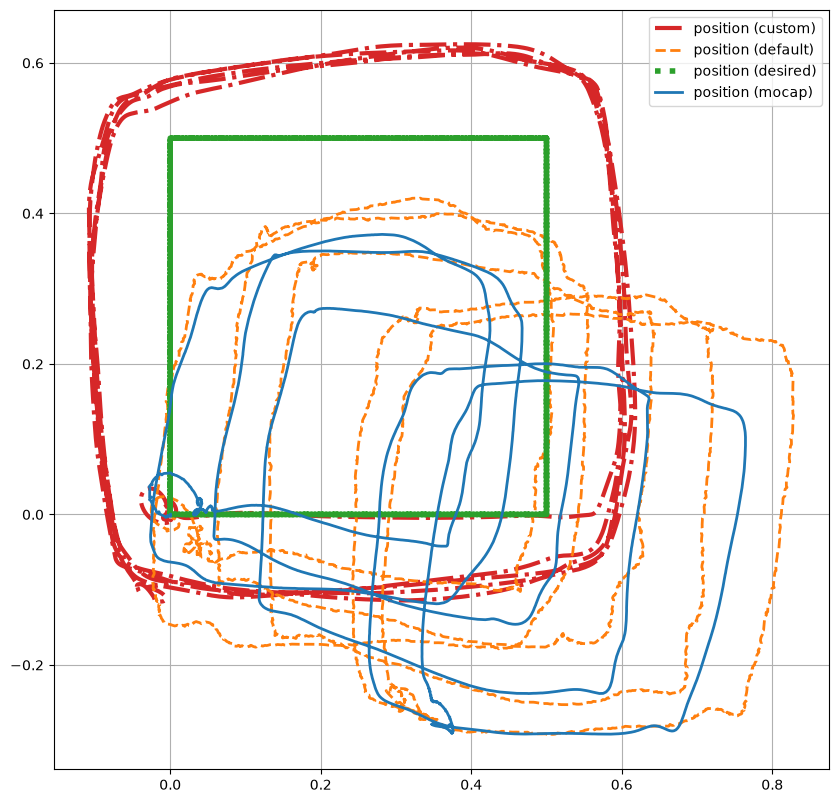

In [35]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.plot(p_x_custom, p_y_custom, label='position (custom)',
         color=custom_color, linestyle=custom_linestyle, linewidth=custom_linewidth)
ax.plot(p_x_default, p_y_default, label='position (default)',
         color=default_color, linestyle=default_linestyle, linewidth=default_linewidth)
ax.plot(p_x_des, p_y_des, label='position (desired)',
         color=desired_color, linestyle=desired_linestyle, linewidth=desired_linewidth)
ax.plot(p_x_mocap, p_y_mocap, label='position (mocap)',
         color=mocap_color, linestyle=mocap_linestyle, linewidth=mocap_linewidth)
ax.set_aspect('equal')
ax.legend()
ax.grid()
plt.show()

I used my custom controller and observer with motion capture. I commanded five squares with 0.50 m sides at a height of 0.50 m, moving at 0.20 m/s and pausing for 1 second at each corner before landing.

Also, evaluate the following cell to show links to a video of your hardware flight test (change the url as appropriate) that was previously uploaded to [Illinois Mediaspace](https://mediaspace.illinois.edu/) and published as **Unlisted**.

In [38]:
# FIXME (REPLACE URL TO SHOW A VIDEO OF YOUR FLIGHT)
mediaspace('https://mediaspace.illinois.edu/media/t/1_6r316eyy')

**Modify the text in this cell** to explain what is going on in the video and in the plots. What happens over time to the state estimates from the default and custom observers, relative to the state estimates from the motion capture system? Is the drone really flying in squares? To what extent is the custom controller working well? To what extent is the custom observer working well? How could you improve performance? What is possible to improve, and what is impossible to improve, given the available sensors?

The drone flies in a square pattern, but the corners are rounded and the path drifts with each lap. The default observer follows the mocap x/y data more closely. My custom observer shows nearly the same loop each time, even while mocap shows the drone moving away. Height stays close to 0.50 m also.

The controller handles height and changes in direction reasonably well, but its position tracking suffers when the estimates drift. Better sensor calibration could reduce bias, and gain tuning could reduce overshoot. But, the sensors don’t directly measure absolute horizontal position or yaw, so correcting that drift reliably would need an additional reference.

# 5. Reflect

**Modify the text in this cell** to describe, in at least two or three sentences, the biggest struggle you had (with the technical material, with collaboration, etc.) and the most important thing that you learned. Look back at your reflection from Labs 5 and 6 — have you taken a step forward?

Probably understanding why drifting happened. So the observer estimates postion by adding up velocity estimates over time, and so the small errors add up over time so the estimated postion moves away from the real position. Now the controller follows this estimate, so the drone can drift while it thinks it s staying where it should be. 